# ARMA Models

**Reference:** Shumway, R. H., & Stoffer, D. S. (2019). *Time Series: A Data Analysis Approach Using R*. Chapman & Hall/CRC Press.

**Notation:** $x_t$ is the observation at time $t$; $w_t$ is a zero-mean white-noise innovation with variance $\sigma_w^2$; $B$ is the backshift operator, $Bx_t=x_{t-1}$. All displayed equations use Markdown-compatible LaTeX.

### R packages and reproducibility

`astsa` provides `tsplot()`, `acf2()`, `acf1()`, `sarima()`, `sarima.for()` and the example datasets. All other functions below are in base R or standard R packages. Run the setup cell once per Colab runtime; package installation can take longer on the first run.

In [1]:
packages = c("astsa")
missing = packages[!sapply(packages, requireNamespace, quietly=TRUE)]
if (length(missing) > 0) install.packages(missing, repos="https://cloud.r-project.org")
library(astsa)
options(digits=5)
par(mfrow=c(1,1))

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



### Autoregressive process: AR($p$)

**Autoregression (AR)** means that the current observation depends linearly on its *own past values*. The order $p$ is the number of lagged observations included. **Lag $h$** means $h$ observation intervals into the past; an **innovation** $w_t$ is the new unpredictable disturbance at time $t$.

$$x_t=\alpha+\phi_1x_{t-1}+\cdots+\phi_px_{t-p}+w_t.$$

Here $\alpha$ is the constant, $\phi_j$ is the coefficient on lag $j$, and $\sigma_w^2=\operatorname{Var}(w_t)$. For a stationary model with mean $\mu$, $\alpha=\mu(1-\sum_{j=1}^{p}\phi_j)$. These $\phi_j$ values are not unrestricted: a causal stationary AR model requires roots of $1-\phi_1z-\cdots-\phi_pz^p$ to lie outside the unit circle.

### AR(1): stationarity, causality, variance, and ACF

For a zero-mean AR(1),

$$x_t=\phi x_{t-1}+w_t,\qquad |\phi|<1.$$

**Stationarity** means a constant unconditional mean and variance, with autocovariance depending only on lag. **Causality** means $x_t$ can be written using current and past innovations only:

$$x_t=\sum_{j=0}^{\infty}\phi^j w_{t-j}.$$

For $|\phi|<1$,

$$\operatorname{E}(x_t)=0,\quad \gamma(h)=\frac{\sigma_w^2\phi^{|h|}}{1-\phi^2},\quad \rho(h)=\phi^{|h|},\quad \gamma(0)=\frac{\sigma_w^2}{1-\phi^2}.$$

$\gamma(h)$ is **autocovariance** at lag $h$, $\rho(h)$ is the corresponding **autocorrelation** (ACF), and $\gamma(0)$ is variance. Positive $\phi$ gives same-direction persistence; negative $\phi$ produces alternating signs of short-lag correlation. An AR(1) with $\phi=1$ is a random walk, so the stationary formulas above do not apply.

   phi theoretical_variance theoretical_acf_lag1 theoretical_acf_lag2
1  0.9               5.2632                  0.9                 0.81
2 -0.9               5.2632                 -0.9                 0.81
  theoretical_acf_lag3
1                0.729
2               -0.729


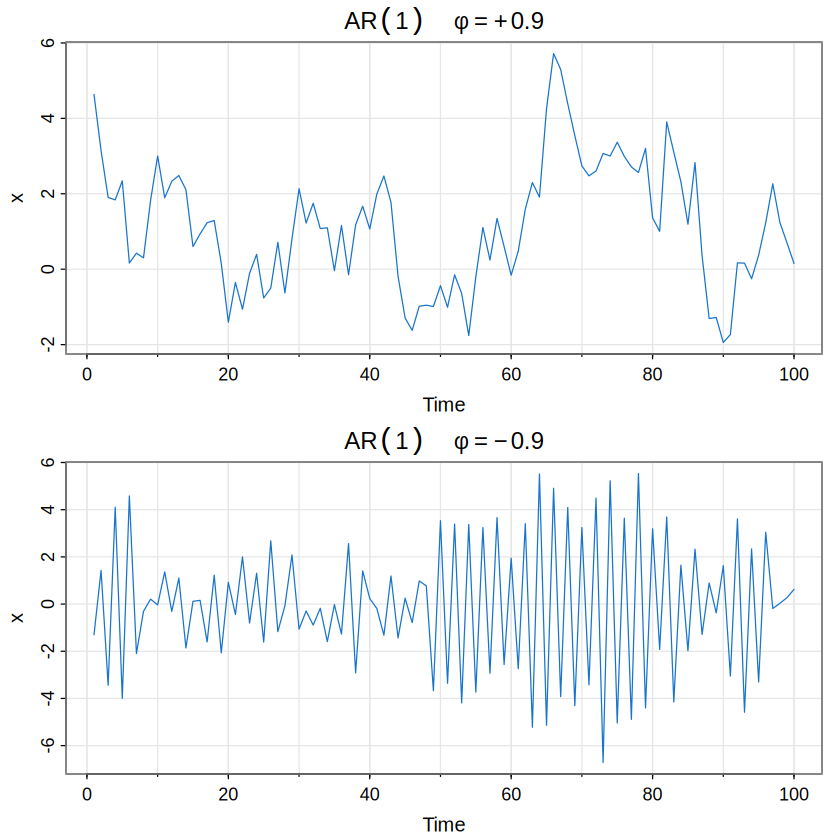

In [2]:
phi = c(.9, -.9)
comparison = data.frame(phi=phi,
                        theoretical_variance=1/(1-phi^2),
                        theoretical_acf_lag1=phi,
                        theoretical_acf_lag2=phi^2,
                        theoretical_acf_lag3=phi^3)
print(comparison)
set.seed(90210)
par(mfrow=c(2,1))
tsplot(arima.sim(list(order=c(1,0,0), ar=.9), n=100),
       ylab="x", col=4, main=expression(AR(1)~~phi==+.9))
tsplot(arima.sim(list(order=c(1,0,0), ar=-.9), n=100),
       ylab="x", col=4, main=expression(AR(1)~~phi==-.9))
par(mfrow=c(1,1))

**Interpretation.** The horizontal axis is the observation index and the vertical axis is the simulated $x_t$. With $\phi=0.9$, neighboring values tend to have the same sign and the path changes more smoothly. With $\phi=-0.9$, neighbors tend to alternate; both models have the same theoretical variance $1/(1-0.9^2)\approx5.263$, because variance depends on $\phi^2$. For the positive case, $\rho(2)=0.81$; for the negative case, $\rho(2)=0.81$ as well, despite opposite lag-1 signs. A finite simulation will not exactly match the theoretical moments.

### AR(2): innovation-response ($\psi$) weights

For

$$x_t=1.5x_{t-1}-0.75x_{t-2}+w_t,$$

a causal **infinite moving-average representation** has

$$x_t=\sum_{j=0}^{\infty}\psi_jw_{t-j},\qquad \psi_0=1.$$

A $\psi_j$ coefficient measures how much an innovation at time $t-j$ contributes to $x_t$. The weights obey

$$\psi_1=1.5,\qquad \psi_j=1.5\psi_{j-1}-0.75\psi_{j-2}\quad(j\ge2).$$

For example, $\psi_2=1.5(1.5)-0.75(1)=1.5$. Their damped oscillation creates pseudo-cycles. **Pseudo-cyclic** means fluctuations resemble cycles without an exactly repeating deterministic waveform.

 [1]  1.000  1.500  1.500  1.125  0.562  0.000 -0.422 -0.633 -0.633 -0.475


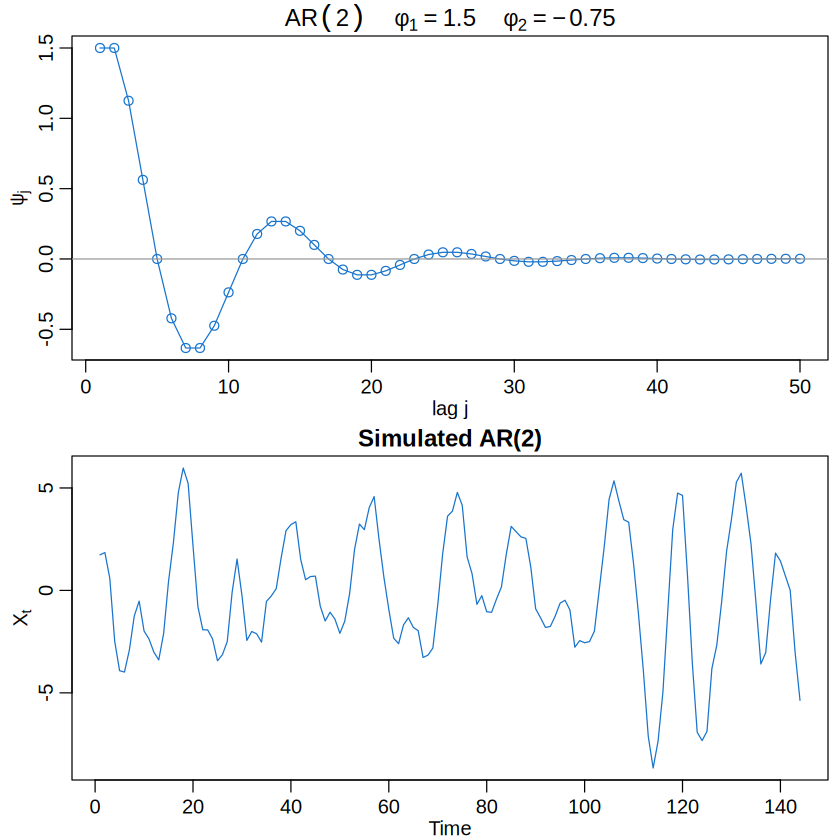

In [3]:
psi = ARMAtoMA(ar=c(1.5,-.75), ma=0, lag.max=50)
print(round(c(1,psi[1:9]),3))  # includes psi[0]=1 first
par(mfrow=c(2,1), mar=c(2,2.5,1,0)+.5, mgp=c(1.5,.6,0))
plot(1:50, psi, type="o", col=4, xlab="lag j", ylab=expression(psi[j]),
     main=expression(AR(2)~~phi[1]==1.5~~phi[2]==-.75))
abline(h=0, col=gray(.6))
set.seed(8675309)
simulation = arima.sim(list(order=c(2,0,0), ar=c(1.5,-.75)), n=144)
plot(simulation, ylab=expression(X[t]), col=4, main="Simulated AR(2)")
par(mfrow=c(1,1))

**Interpretation.** In the first panel, the horizontal axis is the innovation lag $j$, and the vertical axis gives $\psi_j$. Alternating positive and negative weights indicate an oscillatory impulse response, while decreasing magnitudes indicate fading influence of past shocks. The second panel shows corresponding oscillations in $x_t$ over 144 observation periods. The cycles are approximate because innovations arrive at every time step.

### Moving-average process: MA($q$)

A **moving-average (MA) model** combines the current and a finite number of *past shocks* (not averages of recent observations, as in smoothing):

$$x_t=w_t+\theta_1w_{t-1}+\cdots+\theta_qw_{t-q}.$$

Here $q$ is the number of lagged innovations and $\theta_j$ measures the effect of shock $w_{t-j}$. Every finite MA($q$) process driven by white noise is weakly stationary. The ACF becomes exactly zero beyond lag $q$; this is called an **ACF cutoff**.

### MA(1): theoretical dependence

$$x_t=w_t+\theta w_{t-1},\qquad \gamma(0)=(1+\theta^2)\sigma_w^2.$$

$$\gamma(1)=\theta\sigma_w^2,\qquad \rho(1)=\frac{\theta}{1+\theta^2},\qquad \rho(h)=0\quad(|h|>1).$$

For $\theta=0.9$, $\rho(1)=0.9/1.81\approx0.4972$; for $\theta=-0.9$, $\rho(1)\approx-0.4972$. In either case, the theoretical correlations beyond lag 1 are zero. This contrasts with an AR(1), whose theoretical ACF decays but does not cut off.

  theta theoretical_acf_lag1 theoretical_variance
1   0.9              0.49724                 1.81
2  -0.9             -0.49724                 1.81


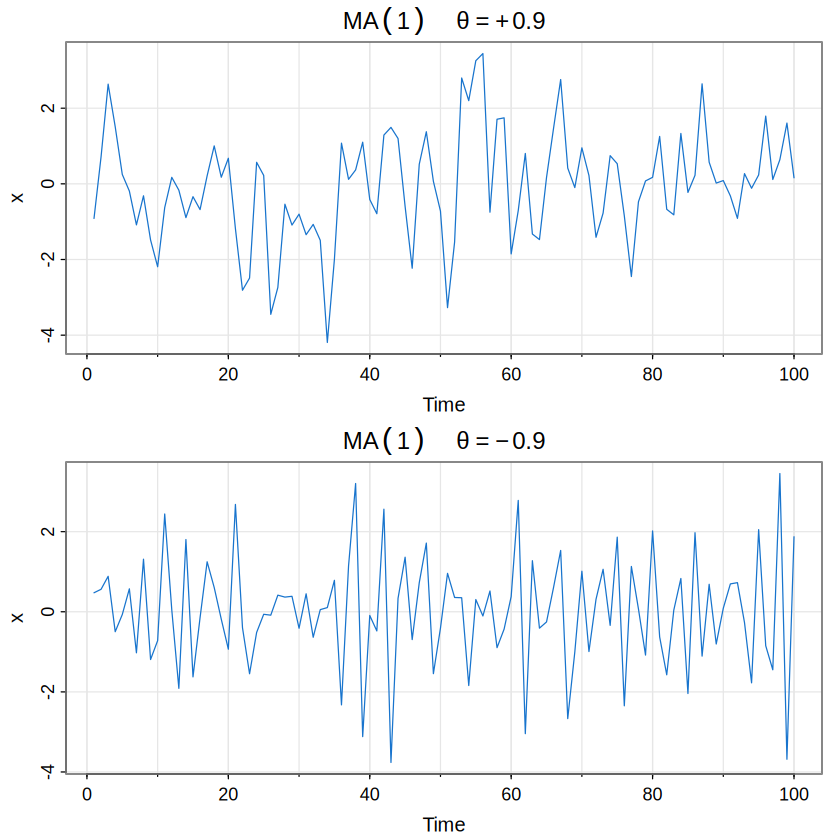

In [4]:
theta = c(.9,-.9)
print(data.frame(theta=theta, theoretical_acf_lag1=theta/(1+theta^2),
                 theoretical_variance=1+theta^2))
set.seed(90210)
par(mfrow=c(2,1))
tsplot(arima.sim(list(order=c(0,0,1), ma=.9), n=100), col=4,
       ylab="x", main=expression(MA(1)~~theta==+.9))
tsplot(arima.sim(list(order=c(0,0,1), ma=-.9), n=100), col=4,
       ylab="x", main=expression(MA(1)~~theta==-.9))
par(mfrow=c(1,1))

**Interpretation.** The MA(1) with positive $\theta$ tends to show locally similar adjacent values, while negative $\theta$ creates short-run alternation. The theoretical variance is $1+0.9^2=1.81$ in both cases when $\sigma_w^2=1$. The labels use $\theta=\pm0.9$, matching the simulation parameters.

### Invertibility and non-unique MA descriptions

**Invertibility** means past and current observations can recover innovations using a convergent representation. For MA(1),

$$w_t=\sum_{j=0}^{\infty}(-\theta)^jx_{t-j},\qquad |\theta|<1.$$

Two MA(1) models can have exactly the same second-order behavior. For $(\theta,\sigma_w^2)=(5,1)$ and $(0.2,25)$:

$$\gamma(0)=(1+\theta^2)\sigma_w^2=26,\qquad \gamma(1)=\theta\sigma_w^2=5.$$

The invertible parameterization is $\theta=0.2$ because its absolute value is below 1. When innovations are Gaussian, the two models also have the same joint distribution.

In [5]:
candidates = data.frame(theta=c(5,1/5), innovation_variance=c(1,25))
candidates$gamma0 = (1+candidates$theta^2)*candidates$innovation_variance
candidates$gamma1 = candidates$theta*candidates$innovation_variance
candidates$rho1 = candidates$gamma1/candidates$gamma0
candidates$invertible = abs(candidates$theta) < 1
print(candidates)

  theta innovation_variance gamma0 gamma1    rho1 invertible
1   5.0                   1     26      5 0.19231      FALSE
2   0.2                  25     26      5 0.19231       TRUE


### ARMA($p,q$): combining autoregressive terms and moving-average shocks

$$x_t=\alpha+\sum_{j=1}^{p}\phi_jx_{t-j}+w_t+\sum_{k=1}^{q}\theta_kw_{t-k}.$$

An **ARMA** model includes both past observations (AR part) and past innovations (MA part). Causality restricts the AR polynomial, while invertibility restricts the MA polynomial. For mean $\mu$ and backshift $B$:

$$\phi(B)(x_t-\mu)=\theta(B)w_t,$$

$$\phi(B)=1-\phi_1B-\cdots-\phi_pB^p,\qquad \theta(B)=1+\theta_1B+\cdots+\theta_qB^q.$$

Both polynomials should have no common factors; otherwise the fitted orders include redundant parameters.

### Parameter redundancy: a model that only looks complicated

Multiplying white noise by $(1-0.9B)$ on both sides gives

$$(1-0.9B)x_t=(1-0.9B)w_t.$$

This looks like ARMA(1,1), with $\phi=0.9$ and $\theta=-0.9$, but it reduces to $x_t=w_t$. Significant-looking AR and MA terms with almost cancelling coefficients may reflect **over-parameterization**, not meaningful dynamics. The following simulation reproduces the book's cautionary example; exact fitted coefficients can vary with R version and optimizer.

In [6]:
set.seed(8675309)
x = rnorm(150, mean=5)
fit_redundant = arima(x, order=c(1,0,1))
print(fit_redundant)
cat("Sample mean:", mean(x), "
")
cat("Sample lag-1 ACF:", as.numeric(acf(x, plot=FALSE, lag.max=1)$acf[2]), "
")


Call:
arima(x = x, order = c(1, 0, 1))

Coefficients:
         ar1    ma1  intercept
      -0.960  0.953      5.046
s.e.   0.169  0.175      0.073

sigma^2 estimated as 0.799:  log likelihood = -195.98,  aic = 399.96
Sample mean: 5.0459 
Sample lag-1 ACF: -0.026108 


**Interpretation of the executed result.** The simulated observations are independent normal values with theoretical mean 5. The sample mean is **5.0459** and the sample lag-1 ACF is **−0.0261**, close to zero. Nevertheless, the fitted ARMA(1,1) reports `ar1 = −0.960` (SE 0.169) and `ma1 = 0.953` (SE 0.175). These coefficients nearly cancel because the AR factor $1+0.960B$ and MA factor $1+0.953B$ are almost equal. Their large magnitudes therefore do **not** establish meaningful serial dependence. The fitted `intercept = 5.046` represents the stationary mean, not the recursion's constant term. This is a concrete example of near-parameter redundancy: inspect common factors and the observed ACF before interpreting apparently large coefficients.


### Polynomial roots and common factors

For

$$(1-0.3B-0.4B^2)x_t=(1+0.5B)w_t,$$

$$1-0.3B-0.4B^2=(1+0.5B)(1-0.8B).$$

The common factor cancels, leaving $x_t=0.8x_{t-1}+w_t$ (under the causal and invertible interpretation). `polyroot()` returns the roots in the backshift variable $B$; a common root of $-2$ reveals redundancy.

In [7]:
AR = c(1,-.3,-.4)
MA = c(1,.5)
print(polyroot(AR))
print(polyroot(MA))
cat("Expected simplified AR coefficient:", .8, "
")

[1]  1.25-3.213e-18i -2.00+3.213e-18i
[1] -2+0i
Expected simplified AR coefficient: 0.8 


### Causal and invertible representations of ARMA(1,1)

For $x_t=0.8x_{t-1}+w_t-0.5w_{t-1}$,

$$x_t=w_t+0.3w_{t-1}+0.24w_{t-2}+\cdots,$$

and an invertible shock representation begins

$$w_t=x_t-0.3x_{t-1}-0.15x_{t-2}-\cdots.$$

`ARMAtoMA()` returns $\psi_1,\psi_2,\ldots$ (it omits $\psi_0=1$); `ARMAtoAR()` returns the coefficients in $x_t=\sum_{j\ge1}a_jx_{t-j}+w_t$. Thus the coefficients for $w_t$ in terms of the data are their **negatives**.

In [8]:
print(round(ARMAtoMA(ar=.8, ma=-.5, lag.max=10), 2))
print(round(ARMAtoAR(ar=.8, ma=-.5, lag.max=10), 2))
print(ARMAtoMA(ar=1, ma=0, lag.max=12))

 [1] 0.30 0.24 0.19 0.15 0.12 0.10 0.08 0.06 0.05 0.04
 [1] -0.30 -0.15 -0.08 -0.04 -0.02 -0.01  0.00  0.00  0.00  0.00
 [1] 1 1 1 1 1 1 1 1 1 1 1 1


**Interpretation.** Decaying impulse-response weights indicate a stationary causal representation. With `ar=1`, the returned values stay at 1 instead of decaying, consistent with a unit-root random walk that does not satisfy stationary ARMA assumptions.

### Theoretical ACF: AR, MA, and ARMA

For MA($q$), with $\theta_0=1$,

$$\gamma(h)=\sigma_w^2\sum_{j=0}^{q-h}\theta_j\theta_{j+h}\quad(0\le h\le q),\qquad \gamma(h)=0\quad(h>q).$$

For a causal ARMA model written $x_t=\sum_{j\ge0}\psi_jw_{t-j}$,

$$\rho(h)=\frac{\sum_{j=0}^{\infty}\psi_{j+h}\psi_j}{\sum_{j=0}^{\infty}\psi_j^2}\quad(h\ge0).$$

A **cutoff** means a theoretical correlation equals zero beyond a finite lag; **tails off** means its magnitude decreases over increasingly distant lags. Unlike an MA($q$), the ACF for typical AR and nonredundant ARMA models tails off rather than cutting off.

  lag    AR2   MA1 ARMA11
0   0  1.000 1.000  1.000
1   1  0.857 0.497  0.400
2   2  0.536 0.000  0.320
3   3  0.161 0.000  0.256
4   4 -0.161 0.000  0.205
5   5 -0.362 0.000  0.164
6   6 -0.422 0.000  0.131


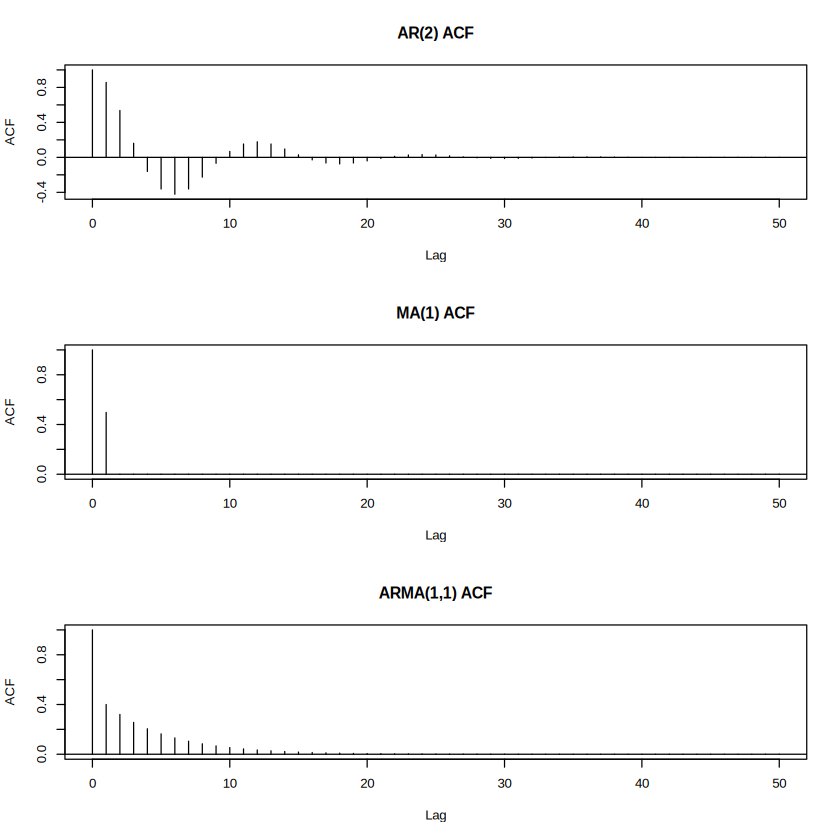

In [9]:
acf_ar2 = ARMAacf(ar=c(1.5,-.75), ma=0, lag.max=50)
acf_ma1 = ARMAacf(ar=0, ma=.9, lag.max=50)
acf_arma11 = ARMAacf(ar=.8, ma=-.5, lag.max=50)
par(mfrow=c(3,1))
plot(0:50, acf_ar2, type="h", ylab="ACF", xlab="Lag", main="AR(2) ACF")
abline(h=0)
plot(0:50, acf_ma1, type="h", ylab="ACF", xlab="Lag", main="MA(1) ACF")
abline(h=0)
plot(0:50, acf_arma11, type="h", ylab="ACF", xlab="Lag", main="ARMA(1,1) ACF")
abline(h=0)
par(mfrow=c(1,1))
print(round(data.frame(lag=0:6, AR2=acf_ar2[1:7], MA1=acf_ma1[1:7], ARMA11=acf_arma11[1:7]),3))

**Interpretation of the computed theoretical ACFs.** For the AR(2), correlations are $0.857$ at lag 1, $0.536$ at lag 2, $0.161$ at lag 3, and negative by lag 4 ($-0.161$), displaying damped oscillations. For the MA(1) with $\theta=0.9$, the lag-1 correlation is $0.497$ and **all lags above 1 equal zero**. For the ARMA(1,1) with $\phi=0.8$ and $\theta=-0.5$, the lag-1 ACF is $0.400$, then $0.320$, $0.256$, $0.205$, and so on: each later lag is multiplied by $0.8$. This illustrates the finite ACF cutoff for MA models versus the trailing ACF for AR and ARMA models. These are theoretical values; sampling confidence bands do not apply to these plots.

For $h\ge1$,

$$\rho(h)=\frac{(1+\theta\phi)(\phi+\theta)}{1+2\theta\phi+\theta^2}\,\phi^{h-1}.$$


### Partial autocorrelation function (PACF)

The **PACF at lag $h$** measures linear correlation between $x_t$ and $x_{t-h}$ **after accounting for intervening lags** $x_{t-1},\ldots,x_{t-h+1}$. This removes indirect dependence. For a theoretical AR($p$) with nonzero last coefficient, the PACF cuts off after lag $p$; for MA and general ARMA models it tails off.

For $x_t=1.5x_{t-1}-0.75x_{t-2}+w_t$:

$$\phi_{11}=\rho(1)=\frac{1.5}{1-(-0.75)}=0.8571,\quad \phi_{22}=-0.75,\quad \phi_{hh}=0\;(h>2).$$

Here $\phi_{hh}$ denotes PACF at lag $h$, rather than an AR model coefficient except at the last included AR lag.

  lag     ACF    PACF
1   1  0.8571  0.8571
2   2  0.5357 -0.7500
3   3  0.1607  0.0000
4   4 -0.1607  0.0000
5   5 -0.3616  0.0000
6   6 -0.4219  0.0000


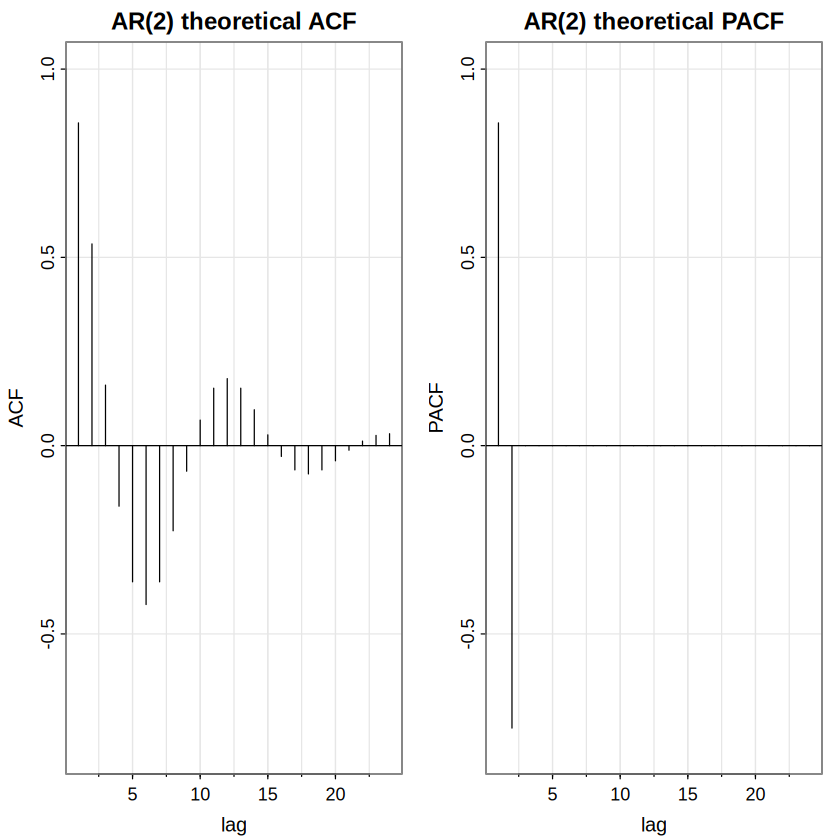

In [10]:
ACF = ARMAacf(ar=c(1.5,-.75), ma=0, lag.max=24)[-1]
PACF = ARMAacf(ar=c(1.5,-.75), ma=0, lag.max=24, pacf=TRUE)
par(mfrow=c(1,2))
tsplot(ACF, type="h", xlab="lag", ylim=c(-.8,1), main="AR(2) theoretical ACF")
abline(h=0)
tsplot(PACF, type="h", xlab="lag", ylim=c(-.8,1), main="AR(2) theoretical PACF")
abline(h=0)
par(mfrow=c(1,1))
print(round(data.frame(lag=1:6, ACF=ACF[1:6], PACF=PACF[1:6]),4))

**Interpretation.** The PACF should show approximately $0.857$ at lag 1, $-0.75$ at lag 2, and theoretical zero thereafter. These values support the AR(2) order directly. In real sample PACF plots, coefficients at higher lags will usually fluctuate around zero because of sampling error; an apparent isolated spike is not automatically evidence for a higher-order AR process.

### ACF/PACF identification guide

| Model | Theoretical ACF | Theoretical PACF |
|---|---|---|
| AR($p$) | Tails off | Cuts off after $p$ |
| MA($q$) | Cuts off after $q$ | Tails off |
| ARMA($p,q$) | Generally tails off | Generally tails off |

This is a preliminary identification tool, not a definitive model test. Differencing, trends, seasonality, sample size and redundant factors can change how an empirical plot looks.

### Recruitment: sample ACF/PACF and AR(2) via OLS

The Recruitment dataset contains monthly observations. `acf2(rec,48)` shows correlations through 48 months (the lag axis may be displayed in years because frequency is 12). `ar.ols()` estimates an AR(2) from observed lagged values. The **intercept** is $\alpha$ in $x_t=\alpha+\phi_1x_{t-1}+\phi_2x_{t-2}+w_t$; it is **not** the unconditional mean $\mu=\alpha/(1-\phi_1-\phi_2)$.

ACF,0.92,0.78,0.63,0.48,0.36,0.26,0.18,0.13,0.09,0.07,⋯,0.01,-0.02,-0.03,-0.03,-0.02,0.01,0.06,0.12,0.17,0.20
PACF,0.92,-0.44,-0.05,-0.02,0.07,-0.03,-0.03,0.04,0.05,-0.02,⋯,0.05,0.08,-0.02,-0.01,-0.02,0.05,0.01,0.05,0.08,-0.04



Call:
ar.ols(x = rec, order.max = 2, demean = FALSE, intercept = TRUE)

Coefficients:
     1       2  
 1.354  -0.463  

Intercept: 6.74 (1.11) 

Order selected 2  sigma^2 estimated as  89.7

$x.mean
[1] 1.1106

$ar
[1] 0.041789 0.041879

AR(2) phi1, phi2: 1.3541 -0.46318 
Unconditional mean implied by AR(2):  


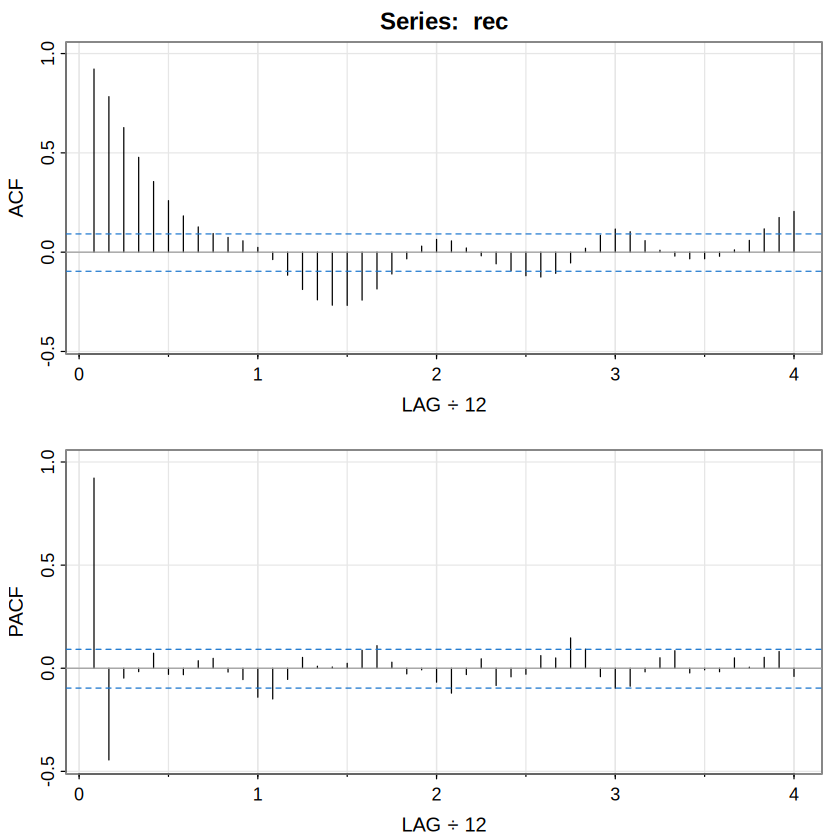

In [11]:
acf2(rec, 48)
(regr = ar.ols(rec, order=2, demean=FALSE, intercept=TRUE))
print(regr$asy.se.coef)
phi_ols = as.numeric(regr$ar)
cat("AR(2) phi1, phi2:", phi_ols, "
")
cat("Unconditional mean implied by AR(2):", as.numeric(regr$intercept)/(1-sum(phi_ols)), "
")

**Interpretation of the executed result.** The Recruitment ACF is approximately **0.92 at lag 1**, **0.78 at lag 2**, and declines afterward. The PACF is **0.92 at lag 1**, **−0.44 at lag 2**, and much smaller thereafter, which supports considering an AR(2). The OLS estimates are $\widehat\phi_1=1.3541$, $\widehat\phi_2=-0.4632$, and intercept $\widehat\alpha=6.74$ (reported SE 1.11), with estimated innovation variance about **89.7**. The intercept is the constant in $x_t=\alpha+\phi_1x_{t-1}+\phi_2x_{t-2}+w_t$, *not* the unconditional series mean. The implied stationary mean is $\mu=\alpha/(1-\phi_1-\phi_2)$, approximately **61.8**. A first AR coefficient above one does not independently mean instability; causality depends on the roots of the complete AR polynomial. The ACF/PACF are useful for choosing a candidate order, but residual diagnostics are still needed.


### Yule–Walker method of moments

**Method of moments** matches theoretical autocorrelations to their observed sample estimates. For AR($p$), the **Yule–Walker equations** are

$$\rho(h)=\sum_{j=1}^{p}\phi_j\rho(h-j),\qquad h=1,\ldots,p,$$

$$\sigma_w^2=\gamma(0)\left(1-\sum_{j=1}^{p}\phi_j\rho(j)\right).$$

For AR(1), $\widehat\phi=\widehat\rho(1)$ and $\widehat\sigma_w^2=\widehat\gamma(0)(1-\widehat\phi^2)$. Here **innovation variance** is the variance of the unpredictable noise, not the variance of the observed series.

In [12]:
rec.yw = ar.yw(rec, order=2)
print(rec.yw$x.mean)
print(rec.yw$ar)
print(sqrt(diag(rec.yw$asy.var.coef)))
print(rec.yw$var.pred)
comparison = data.frame(method=c("OLS","Yule-Walker"),
                        phi1=c(as.numeric(regr$ar[1]),rec.yw$ar[1]),
                        phi2=c(as.numeric(regr$ar[2]),rec.yw$ar[2]))
print(comparison)

[1] 62.263
[1]  1.33159 -0.44454
[1] 0.042226 0.042226
[1] 94.799
       method   phi1     phi2
1         OLS 1.3541 -0.46318
2 Yule-Walker 1.3316 -0.44454


**Interpretation of the executed result.** Yule–Walker gives $\widehat\mu=62.263$, $\widehat\phi_1=1.33159$, $\widehat\phi_2=-0.44454$, and innovation variance **94.799**. Approximate coefficient standard errors are **0.04223** each. OLS gives $\widehat\phi_1=1.3541$ and $\widehat\phi_2=-0.46318$. The methods agree on a strong positive first lag and negative second lag, but give slightly different finite-sample estimates. The innovation variances from different estimation methods should not be interpreted as a standalone out-of-sample ranking.


### MA(1) moment estimator and its limitation

For invertible MA(1),

$$\widehat\rho(1)=\frac{\widehat\theta}{1+\widehat\theta^2}\implies\widehat\rho(1)\widehat\theta^2-\widehat\theta+\widehat\rho(1)=0.$$

The invertible solution when the empirical correlation is nonzero and $|\widehat\rho(1)|\le1/2$ is

$$\widehat\theta=\frac{1-\sqrt{1-4\widehat\rho(1)^2}}{2\widehat\rho(1)}.$$

When $\widehat\rho(1)=0$, take $\widehat\theta=0$. The quadratic has no real solution if the sample ACF exceeds $0.5$ in magnitude, even when the true process is MA(1); sampling variability can produce this situation.

In [13]:
set.seed(2)
ma1 = arima.sim(list(order=c(0,0,1), ma=.9), n=50)
r1 = as.numeric(acf1(ma1, plot=FALSE)[1])
cat("Sample lag-1 ACF:", round(r1,4), "
")
cat("Theoretical lag-1 ACF:", .9/(1+.9^2), "
")
if (abs(r1) <= .5) {
  theta_mom = if (abs(r1) < 1e-12) 0 else (1-sqrt(1-4*r1^2))/(2*r1)
  cat("Invertible moment estimate:", theta_mom, "
")
} else {
  cat("No real MA(1) moment solution for this sample ACF.
")
}

Sample lag-1 ACF: 0.5067 
Theoretical lag-1 ACF: 0.49724 
No real MA(1) moment solution for this sample ACF.


**Interpretation of the executed result.** With $\theta=0.9$, the theoretical MA(1) lag-1 ACF is $0.9/(1+0.9^2)=\mathbf{0.49724}$. In the 50-point simulation, the sample estimate is **0.5067**, slightly above the largest possible theoretical MA(1) lag-1 ACF of **0.5**. Hence the moment equation $r=\theta/(1+\theta^2)$ has **no real-valued solution** for this realization. This does not show that the generating model is wrong; it shows that sampling variation can make a moment estimate infeasible, especially near the parameter boundary. Likelihood estimation is an alternative.


### Conditional least squares: shocks must be reconstructed

For ARMA($p,q$), write the innovations recursively as

$$w_t(\boldsymbol\beta)=x_t-\sum_{j=1}^{p}\phi_jx_{t-j}-\sum_{k=1}^{q}\theta_kw_{t-k}(\boldsymbol\beta),$$

where $\boldsymbol\beta$ collects AR and MA coefficients. **Conditional least squares (CSS)** minimizes the sum of squared reconstructed innovations after specifying initial conditions (for example, initial unknown shocks set to zero):

$$S_c(\boldsymbol\beta)=\sum_{t=p+1}^{n}w_t(\boldsymbol\beta)^2.$$

The dependence of $w_t$ on past reconstructed $w$ makes CSS nonlinear when an MA component is present.

### Gauss–Newton estimation for MA(1)

For $x_t=w_t+\theta w_{t-1}$ with $w_0=0$,

$$w_t(\theta)=x_t-\theta w_{t-1}(\theta),$$

$$z_t(\theta)=-\frac{\partial w_t(\theta)}{\partial\theta}=w_{t-1}(\theta)-\theta z_{t-1}(\theta),\qquad z_0=0.$$

**Gauss–Newton** updates $\theta$ using a local linear approximation to the nonlinear residuals:

$$\theta^{(j+1)}=\theta^{(j)}+\frac{\sum_{t=1}^{n}z_t(\theta^{(j)})w_t(\theta^{(j)})}{\sum_{t=1}^{n}z_t(\theta^{(j)})^2}.$$

Here $j$ indexes *algorithm iterations*, not time; $S_c$ is the **conditional sum of squares**. The numerator captures the residual–derivative association, and the denominator scales the step. Convergence means the updates (and typically the objective) become small, not that the model is necessarily correct.

### Glacial varves: log differences and ACF/PACF

A **log difference** is `diff(log(varve))`: the change in log thickness between successive yearly layers. It often reduces changing scale and trend. A sample ACF with a prominent negative lag-1 correlation followed by small later correlations is consistent with MA(1); this remains a tentative identification until residual diagnostics.

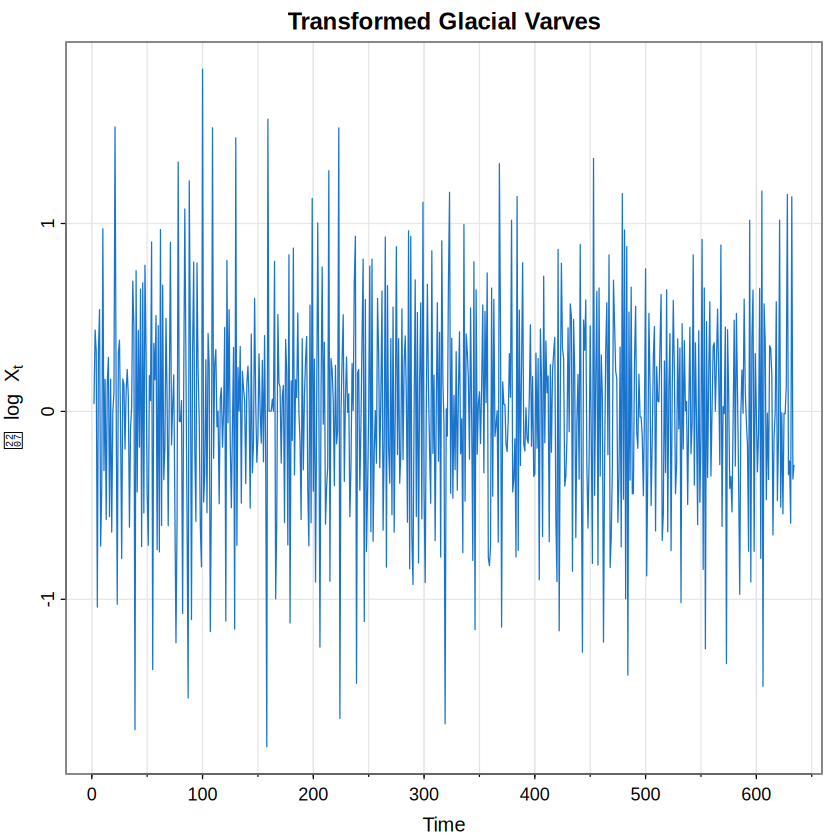

ACF,-0.4,-0.04,-0.06,0.01,0.00,0.04,-0.04,0.04,0.01,-0.05,⋯,0.05,-0.05,0.03,-0.02,0.00,0.06,-0.05,-0.03,0.04,-0.05
PACF,-0.4,-0.24,-0.23,-0.18,-0.15,-0.08,-0.11,-0.05,-0.01,-0.07,⋯,0.03,-0.02,0.00,-0.03,-0.02,0.04,-0.02,-0.02,0.01,-0.07


[1] -0.39743

Number of differenced observations: 633 


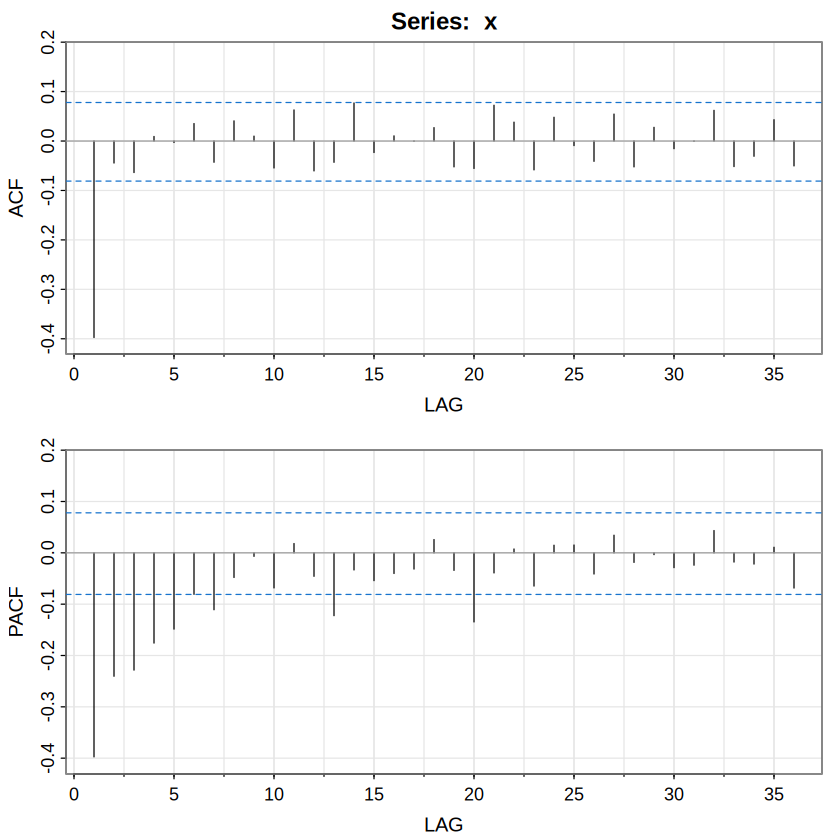

In [14]:
x = diff(log(varve))
tsplot(x, col=4, ylab=expression(nabla~log~X[t]), main="Transformed Glacial Varves")
acf2(x)
(r = as.numeric(acf1(x, 1, plot=FALSE)[1]))
cat("Number of differenced observations:", length(x), "
")

### Gauss–Newton calculation and convergence history

The original initialization $\theta^{(0)}\approx-0.5$ comes from the MA(1) moment formula. The following retains the book's recursive implementation and uses explicit vector initialization and a correctly numbered iteration table. The first observation sets $w_1=x_1$ and $z_1=0$; this corresponds to $w_0=z_0=0$.

In [15]:
num = length(x)
theta0 = if (abs(r) < 1e-12) 0 else if (abs(r) <= .5) (1-sqrt(1-4*r^2))/(2*r) else -.5
niter = 12
w = z = numeric(num)
Sc = Sz = Szw = numeric(niter)
para = numeric(niter+1)
para[1] = theta0
for (j in 1:niter) {
  w[1] = x[1]; z[1] = 0
  for (i in 2:num) {
    w[i] = x[i] - para[j]*w[i-1]
    z[i] = w[i-1] - para[j]*z[i-1]
  }
  Sc[j] = sum(w^2)
  Sz[j] = sum(z^2)
  Szw[j] = sum(z*w)
  para[j+1] = para[j] + Szw[j]/Sz[j]
}
results = data.frame(iteration=0:(niter-1), thetahat=para[1:niter], Sc=Sc, Sz=Sz)
print(results, row.names=FALSE)
cat("Final updated theta:", para[niter+1], "
")
cat("Last evaluated conditional SSE:", Sc[niter], "
")
cat("Approximate innovation variance (book df n-1):", Sc[niter]/(num-1), "
")
cat("Approximate SE (last evaluated):", sqrt((Sc[niter]/(num-1))/Sz[niter]), "
")

 iteration thetahat     Sc     Sz
         0 -0.49469 158.76 171.31
         1 -0.66796 150.79 235.24
         2 -0.73307 149.31 300.41
         3 -0.75618 149.07 336.65
         4 -0.76539 149.03 354.02
         5 -0.76931 149.02 362.04
         6 -0.77104 149.02 365.69
         7 -0.77181 149.02 367.35
         8 -0.77216 149.02 368.10
         9 -0.77231 149.02 368.44
        10 -0.77239 149.02 368.59
        11 -0.77242 149.02 368.66
Final updated theta: -0.77243 
Last evaluated conditional SSE: 149.02 
Approximate innovation variance (book df n-1): 0.23579 
Approximate SE (last evaluated): 0.02529 


**Interpretation of the executed Gauss–Newton table.** The initial moment estimate is $\theta^{(0)}=\mathbf{-0.49469}$. After successive updates, the displayed parameter moves through **−0.66796**, **−0.73307**, and **−0.75618**, reaching approximately **−0.77242** in the final evaluated row. The conditional sum of squares decreases from **158.76** to **149.02**, while $S_z=\sum z_t^2$ increases from **171.31** to **368.66**. The separately printed final updated value is **−0.77243**; this differs slightly because it is the update *after* the final evaluated row. With 632 residual degrees of freedom, the approximate innovation variance is **0.23579** and the curvature-based coefficient SE is **0.02529**. A lower conditional SSE means the reconstructed shocks fit the observations better under this MA(1) specification; convergence alone does not establish model adequacy.


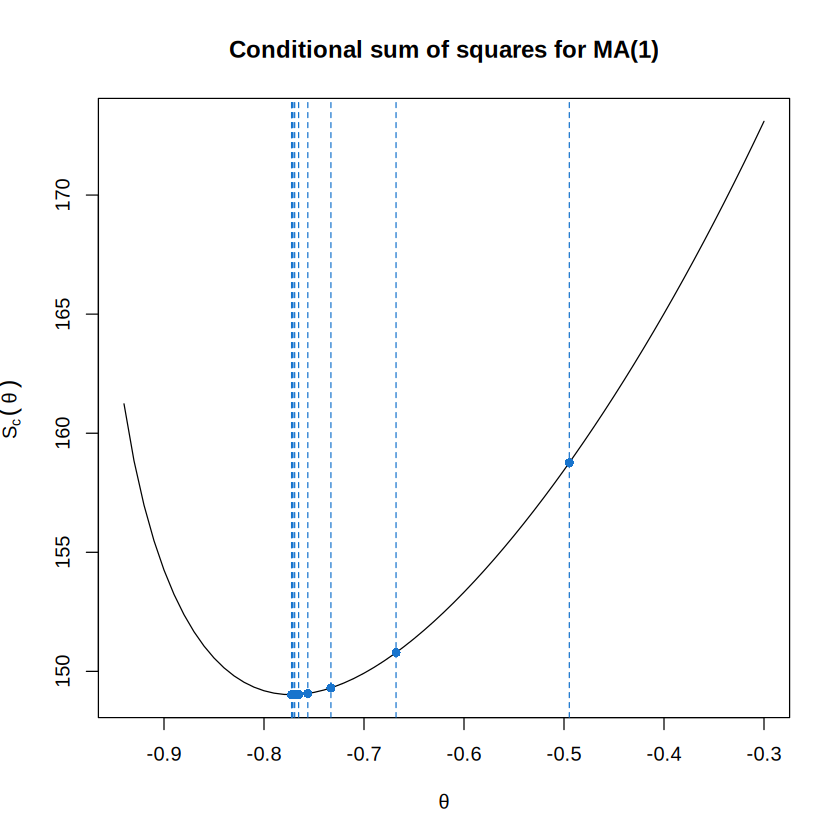

In [16]:
th = -seq(.3,.94,.01)
cSS = numeric(length(th))
for (p in 1:length(th)) {
  w = numeric(num)
  w[1] = x[1]
  for (i in 2:num) w[i] = x[i]-th[p]*w[i-1]
  cSS[p] = sum(w^2)
}
plot(th, cSS, type="l", ylab=expression(S[c](theta)), xlab=expression(theta),
     main="Conditional sum of squares for MA(1)")
abline(v=para[1:niter], lty=2, col=4)
points(para[1:niter], Sc, pch=16, col=4)

**Interpretation of the plotted objective.** The horizontal axis shows candidate $\theta$ values, and the vertical axis shows conditional $S_c(\theta)$, the sum of squared recursively reconstructed innovations. The minimum in the displayed range is close to **−0.77**, consistent with the computed **−0.77243** update. Early Gauss–Newton steps are larger, and later steps cluster near the bottom of the curve. The plot supports numerical convergence to a minimum within the examined interval, but does not compare MA(1) against alternative time-series models.


### Maximum likelihood versus conditional least squares

For stationary Gaussian AR(1), the first observation has variance $\sigma_w^2/(1-\phi^2)$, so including its stationary distribution produces an *unconditional* weighted sum of squares:

$$S(\mu,\phi)=(1-\phi^2)(x_1-\mu)^2+\sum_{t=2}^{n}\left[(x_t-\mu)-\phi(x_{t-1}-\mu)\right]^2.$$

**MLE** selects parameters maximizing the probability of the observed data under the specified distribution; for Gaussian ARMA models, exact likelihood estimation incorporates the covariance and initial-state structure. Conditional least squares instead simplifies the starting conditions. `sarima()` runs established estimation procedures, including diagnostics.

initial  value -0.551778 
iter   2 value -0.671626
iter   3 value -0.705973
iter   4 value -0.707314
iter   5 value -0.722372
iter   6 value -0.722738
iter   7 value -0.723187
iter   8 value -0.723194
iter   9 value -0.723195
iter   9 value -0.723195
iter   9 value -0.723195
final  value -0.723195 
converged
initial  value -0.722700 
iter   2 value -0.722702
iter   3 value -0.722702
iter   3 value -0.722702
iter   3 value -0.722702
final  value -0.722702 
converged
<><><><><><><><><><><><><><>
 
Coefficients: 
    Estimate     SE t.value p.value
ma1  -0.7705 0.0341 -22.616       0

sigma^2 estimated as 0.23532 on 632 degrees of freedom 
 
AIC = 1.3988  AICc = 1.3988  BIC = 1.4129 
 
     ma1 
-0.77054 
[1] 0.23532
[1] -440.72


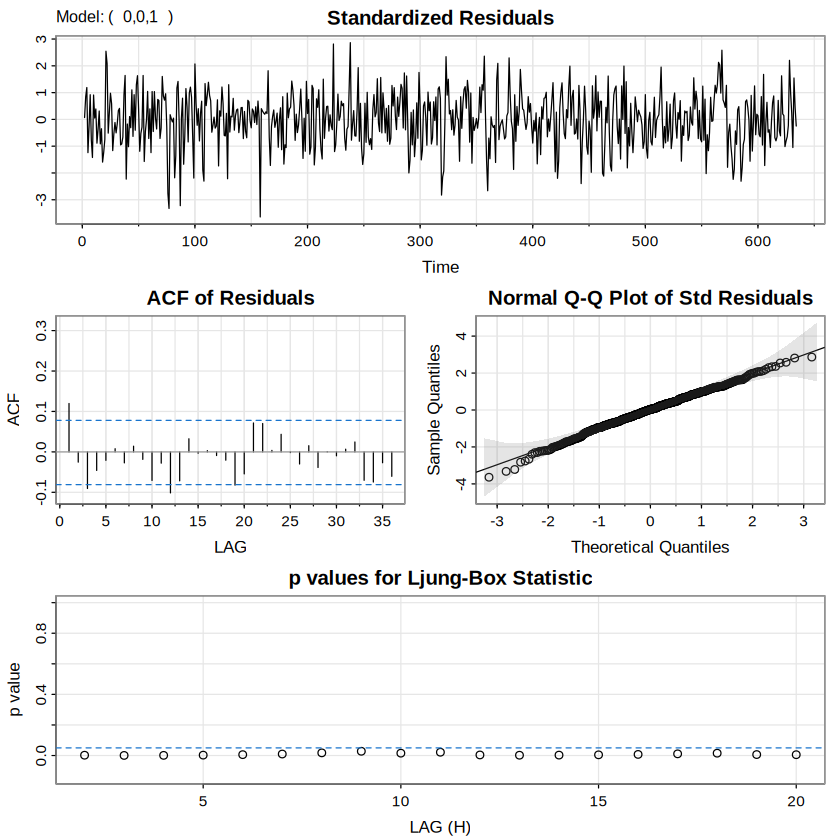

In [17]:
fit_varve = sarima(diff(log(varve)), p=0, d=0, q=1, no.constant=TRUE)
print(fit_varve$fit$coef)
print(fit_varve$fit$sigma2)
print(fit_varve$fit$loglik)

**Interpretation of the executed likelihood fit.** The MA(1) estimate is **−0.7705**, with SE **0.0341** and estimated innovation variance **0.23532**. It is close to the conditional Gauss–Newton value **−0.77243**, although the SE estimates differ (**0.0341** versus **0.02529**) because of different estimation and uncertainty calculations. A negative MA coefficient means consecutive shocks contribute in opposite directions; it does *not* imply that consecutive observed values always alternate. The optimizer reports convergence. The printed `AIC = 1.3988` is the **per-observation** value reported by `sarima()` and should not be confused with the unscaled AIC reported by other R functions. Review the standardized-residual ACF and Ljung–Box diagnostics shown by `sarima()` before treating the model as adequate; a nonsignificant test alone cannot prove that innovations are independent.


### Parameter uncertainty and overfitting

A standard error (SE) measures sampling uncertainty in an estimated parameter. For a large sample from a stationary AR(1), a commonly used approximation is

$$\operatorname{SE}(\widehat\phi)\approx\sqrt{\frac{1-\phi^2}{n}},$$

so an approximate 95% confidence interval is $\widehat\phi\pm1.96\operatorname{SE}(\widehat\phi)$. **Overfitting** means including unnecessary terms, which may increase uncertainty or create cancellation even if the in-sample fit improves. The next simulation compares correctly specified AR(1) to overfitted AR(2).

In [18]:
set.seed(2026)
x_ar1 = arima.sim(list(order=c(1,0,0), ar=.7), n=400)
fit_ar1 = arima(x_ar1, order=c(1,0,0), include.mean=FALSE)
fit_ar2 = arima(x_ar1, order=c(2,0,0), include.mean=FALSE)
print(fit_ar1)
print(fit_ar2)
print(data.frame(model=c("AR(1)","AR(2)"), AIC=c(fit_ar1$aic, fit_ar2$aic),
                 phi1=c(fit_ar1$coef[1],fit_ar2$coef[1]),
                 SE_phi1=c(sqrt(diag(fit_ar1$var.coef))[1],sqrt(diag(fit_ar2$var.coef))[1])))


Call:
arima(x = x_ar1, order = c(1, 0, 0), include.mean = FALSE)

Coefficients:
        ar1
      0.673
s.e.  0.037

sigma^2 estimated as 0.956:  log likelihood = -558.8,  aic = 1121.6

Call:
arima(x = x_ar1, order = c(2, 0, 0), include.mean = FALSE)

Coefficients:
        ar1    ar2
      0.631  0.062
s.e.  0.050  0.050

sigma^2 estimated as 0.952:  log likelihood = -558.04,  aic = 1122.1
  model    AIC    phi1  SE_phi1
1 AR(1) 1121.6 0.67252 0.037011
2 AR(2) 1122.1 0.63096 0.049916


**Interpretation of the executed comparison.** The data were simulated from AR(1) with true $\phi=0.7$. Fitting AR(1) gives $\widehat\phi_1=\mathbf{0.67252}$ (SE **0.03701**) and AIC **1121.6**. Fitting AR(2) gives $\widehat\phi_1=\mathbf{0.63096}$ (SE **0.04992**) and $\widehat\phi_2=\mathbf{0.062}$ (SE **0.050**), with AIC **1122.1**. The estimated extra lag is small relative to its uncertainty; adding it makes the first coefficient less precise (SE increases from 0.037 to 0.050) and does **not** improve AIC in this run. Lower AIC favors the AR(1) among these two fitted models, though the difference of about **0.5** is small and is not strong evidence on its own. This single simulation illustrates the cost of an unnecessary parameter, not a universal guarantee.


### Forecasting a stationary AR(1)

A **forecast horizon** $m$ is the number of future steps predicted beyond the last observed time $n$. With stationary AR(1) and unconditional mean $\mu$,

$$\widehat x_{n+m\mid n}=\mu+\phi^m(x_n-\mu).$$

$\widehat x_{n+m\mid n}$ denotes the prediction of $x_{n+m}$ based on information through time $n$. Its **mean squared prediction error (MSPE)** with known parameters is

$$P_{n+m\mid n}=\sigma_w^2\sum_{j=0}^{m-1}\phi^{2j}=\sigma_w^2\frac{1-\phi^{2m}}{1-\phi^2}.$$

The **root MSPE** is its square root and has the same units as $x_t$. As $m$ increases, forecasts approach $\mu$ and MSPE approaches $\sigma_w^2/(1-\phi^2)$; forecast uncertainty does not keep shrinking.

   horizon forecast root_MSPE lower95 upper95
1        1   13.200    1.0000 11.2400  15.160
2        2   12.560    1.2806 10.0500  15.070
3        3   12.048    1.4316  9.2420  14.854
4        4   11.638    1.5204  8.6583  14.618
5        5   11.311    1.5746  8.2244  14.397
6        6   11.049    1.6084  7.8961  14.201
7        7   10.839    1.6296  7.6448  14.033
8        8   10.671    1.6430  7.4507  13.892
9        9   10.537    1.6516  7.2998  13.774
10      10   10.430    1.6570  7.1817  13.677
11      11   10.344    1.6605  7.0890  13.598
12      12   10.275    1.6627  7.0159  13.534


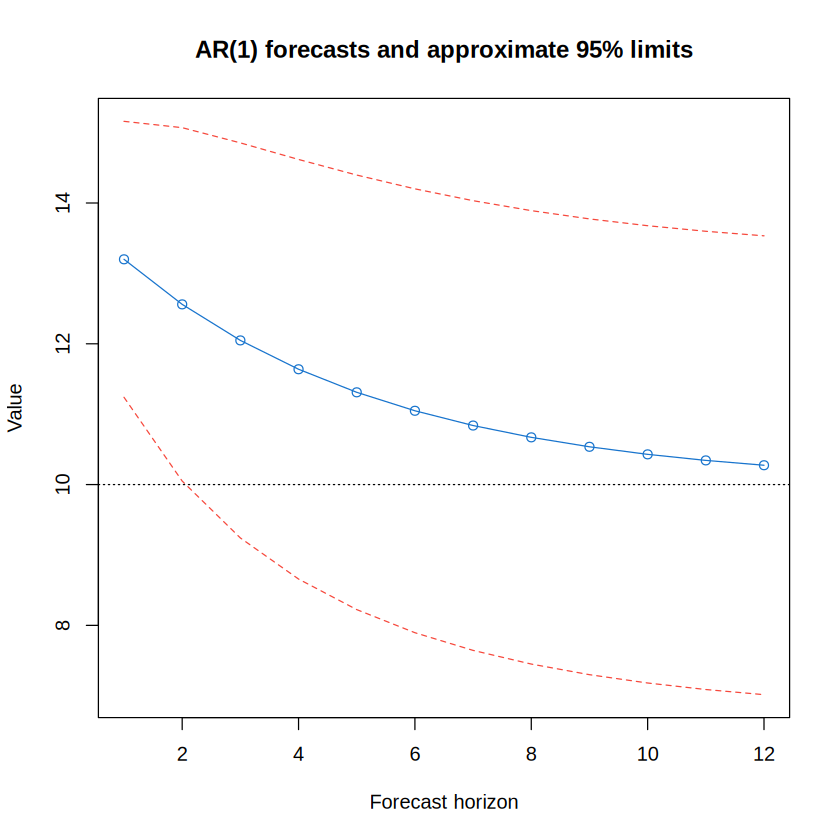

In [19]:
phi = .8; mu = 10; x_n = 14; sigma2 = 1
h = 1:12
forecast = mu + phi^h*(x_n-mu)
mspe = sigma2*(1-phi^(2*h))/(1-phi^2)
forecast_table = data.frame(horizon=h, forecast=round(forecast,4),
                            root_MSPE=round(sqrt(mspe),4),
                            lower95=round(forecast-1.96*sqrt(mspe),4),
                            upper95=round(forecast+1.96*sqrt(mspe),4))
print(forecast_table)
plot(h, forecast, type="o", col=4, ylim=range(forecast_table[,4:5]),
     xlab="Forecast horizon", ylab="Value", main="AR(1) forecasts and approximate 95% limits")
lines(h, forecast_table$lower95, lty=2, col=2)
lines(h, forecast_table$upper95, lty=2, col=2)
abline(h=mu, lty=3)

**Interpretation of the calculated forecasts.** In this numerical illustration $\mu=10$, $\phi=0.8$, $x_n=14$, and $\sigma_w^2=1$. The one-step forecast is **13.200** and its root MSPE is **1.000** (approximate 95% interval **[11.240, 15.160]**). At horizon 2, the forecast is **12.560**, root MSPE **1.281**, and interval about **[10.050, 15.070]**. By horizon 12, the forecast has approached the mean (**10.275**) while root MSPE grows to **1.663** and the interval is approximately **[7.016, 13.534]**. This is mean reversion: as the horizon grows, the influence of $x_n$ shrinks while prediction uncertainty approaches the stationary standard deviation $1/\sqrt{1-0.8^2}\approx1.667$. These intervals presume Gaussian innovations and known model parameters.


### General ARMA prediction uncertainty

For a causal ARMA model expressed as $x_t-\mu=\sum_{j\ge0}\psi_jw_{t-j}$, with $\psi_0=1$, the approximate $m$-step MSPE for a long observed series is

$$P_{n+m\mid n}\approx\sigma_w^2\sum_{j=0}^{m-1}\psi_j^2.$$

Only the future, as-yet-unobserved innovations contribute forecast error when the parameters are known. As the horizon grows, accumulated innovation uncertainty rises toward the marginal process variance. The next example fits AR(2) to actual Recruitment observations.

### Recruitment: AR(2) maximum-likelihood fit and 24-month forecast

`sarima(rec,p=2,d=0,q=0)` fits a stationary AR(2) without differencing. `sarima.for()` computes forecasts and prediction-error bands. Forecasts at distant horizons in a stable AR model tend toward the fitted unconditional mean. The uncertainty bands typically widen before approaching a long-horizon width.

initial  value 3.332380 
iter   2 value 3.251366
iter   3 value 2.564654
iter   4 value 2.430141
iter   5 value 2.258212
iter   6 value 2.253343
iter   7 value 2.248346
iter   8 value 2.248345
iter   9 value 2.248345
iter  10 value 2.248341
iter  11 value 2.248332
iter  12 value 2.248331
iter  13 value 2.248330
iter  13 value 2.248330
iter  13 value 2.248330
final  value 2.248330 
converged
initial  value 2.248862 
iter   2 value 2.248857
iter   3 value 2.248855
iter   4 value 2.248855
iter   5 value 2.248854
iter   6 value 2.248854
iter   7 value 2.248854
iter   8 value 2.248854
iter   9 value 2.248853
iter  10 value 2.248853
iter  10 value 2.248853
iter  10 value 2.248853
final  value 2.248853 
converged
<><><><><><><><><><><><><><>
 
Coefficients: 
      Estimate     SE t.value p.value
ar1     1.3512 0.0416  32.493       0
ar2    -0.4612 0.0417 -11.069       0
xmean  61.8585 4.0039  15.449       0

sigma^2 estimated as 89.334 on 450 degrees of freedom 
 
AIC = 7.3532  AICc = 7.3534 

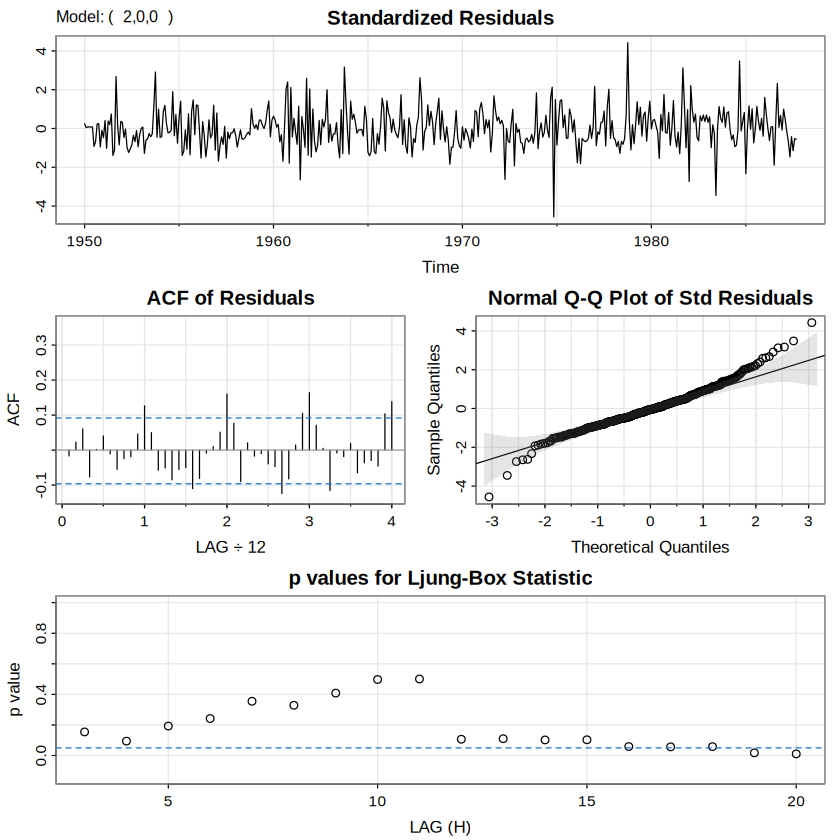

Estimated mean line: 61.858 


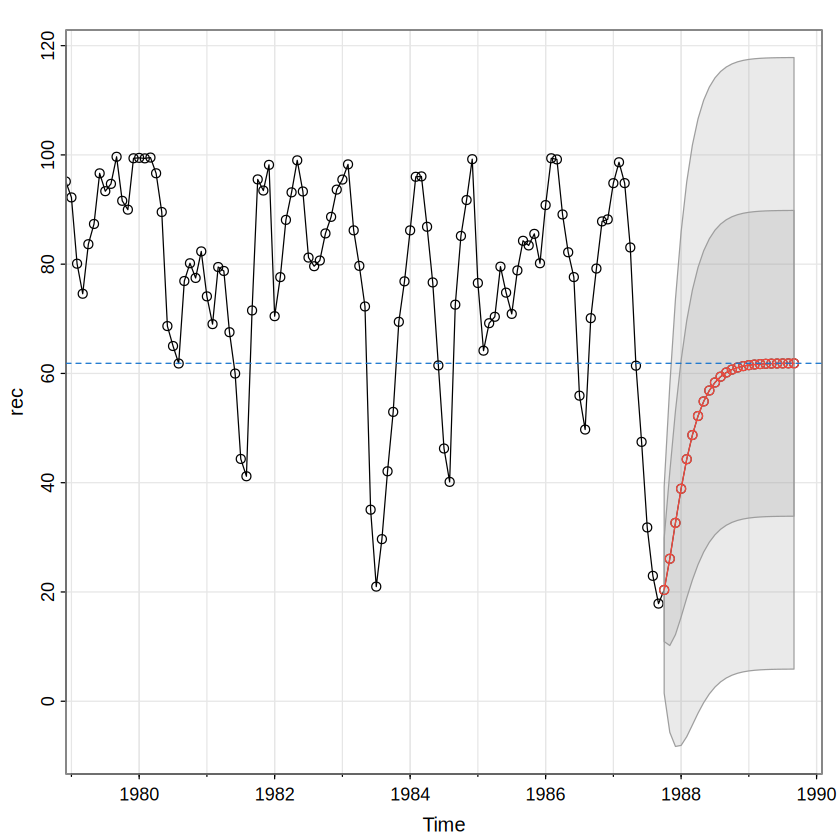

In [20]:
fit_rec = sarima(rec, p=2, d=0, q=0)
print(fit_rec$fit$coef)
print(fit_rec$fit$sigma2)
rec_forecast = sarima.for(rec, n.ahead=24, p=2, d=0, q=0)
rec_mean = if ("intercept" %in% names(fit_rec$fit$coef)) {
  unname(fit_rec$fit$coef["intercept"])
} else if ("xmean" %in% names(fit_rec$fit$coef)) {
  unname(fit_rec$fit$coef["xmean"])
} else mean(rec)
abline(h=rec_mean, col=4, lty=2)
cat("Estimated mean line:", rec_mean, "
")

**Interpretation of the executed Recruitment fit and forecast.** The fitted AR(2) estimates are $\widehat\phi_1=\mathbf{1.35122}$ (SE **0.0416**), $\widehat\phi_2=\mathbf{-0.46121}$ (SE **0.0417**), and stationary mean $\widehat\mu=\mathbf{61.85847}$ (SE **4.0039**). Estimated innovation variance is **89.334**. The 24-month forecast line oscillates while moving toward the horizontal mean near **61.86**; this comes from the AR(2) model's damped dynamics. The forecast bands widen as the horizon increases and eventually approach a steady width associated with long-run variance. The bands express *model-based uncertainty*, not guaranteed limits. The optimizer reports convergence, but statistical adequacy still depends on the residual ACF and Ljung–Box diagnostics shown by `sarima()`; the output should not be interpreted as proof of white-noise residuals.


### Technical checks before selecting an ARMA model

- **Causality and invertibility:** roots of AR and MA polynomials are outside the unit circle.
- **Identifiability:** AR and MA polynomials have no common factor or near-cancelling roots.
- **Residual whiteness:** standardized residual ACF has no clear remaining pattern; investigate diagnostics including Ljung–Box tests.
- **Parsimony:** additional parameters should improve justified fit or predictive performance, not merely the in-sample likelihood.
- **Forecasting:** report horizon, point forecasts, uncertainty, and what the assumptions permit you to conclude.